In [1]:
# Auto-switch to repo root so relative paths (configs/, scripts/, data/) work
from pathlib import Path
import os

_cwd = Path.cwd()
_root = _cwd
while _root != _root.parent:
    if (_root / "configs" / "config.yaml").exists():
        break
    _root = _root.parent
os.chdir(_root)
print(f"Repo root: {_root}")


Repo root: c:\Users\karki\Downloads\main_openworld\openworld


In [2]:
%run scripts/fetch_images.py --subset data/annotations/instances_val_tune2017.stripped.json --dest data/images/val2017 --jobs 16

import json
from pathlib import Path

with open("data/annotations/instances_val_tune2017.stripped.json") as f:
    data = json.load(f)

missing = [
    image["file_name"]
    for image in data["images"]
    if not (Path("data/images/val2017") / image["file_name"]).is_file()
]

print("Images still missing:", len(missing))

INFO: done: ok=0 skipped=500 failed=0 out of 500


Images still missing: 0


# 03 — RPN proposal analysis: base vs novel recall (Phase 3)

Does the detector fail to *find* novel objects, or to *name* them?
This notebook extracts RPN proposals and measures recall@K at IoU 0.5 for base vs novel objects.


In [3]:
%run scripts/extract_proposals.py --config configs/config.yaml --checkpoint outputs/checkpoints/full/epoch_3.pt --image-ids data/splits/val_tune_image_ids.json --annotations data/annotations/instances_val_tune2017.stripped.json --images-root data/images/val2017 --out-dir outputs/proposals/val_tune --top-n 1000

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
processed 500/500
Saved 500 proposal files -> outputs\proposals\val_tune


In [4]:
import json
import torch
from torchvision.ops import box_iou
from pycocotools.coco import COCO
from src.openworld.categories import resolve_categories
from src.openworld.proposals import load_proposals, recall_at, split_gt_by_class

coco = COCO("data/annotations/instances_val_tune2017.stripped.json")
val_ids = json.load(open("data/splits/val_tune_image_ids.json"))
base_ids, novel_ids, _ = resolve_categories("data/annotations/instances_train2017.json")

base_gt, novel_gt = split_gt_by_class(coco, val_ids, base_ids, novel_ids)

print(f"GT base instances : {sum(len(v) for v in base_gt.values())}")
print(f"GT novel instances: {sum(len(v) for v in novel_gt.values())}")

for topn in (100, 300, 1000):
    rb_list, rn_list = [], []
    for iid in val_ids:
        prop = load_proposals(iid, "outputs/proposals/val_tune")
        pb = torch.tensor(prop["boxes"])
        if iid in base_gt:
            rb_list.append(recall_at(torch.stack(base_gt[iid]), pb))
        if iid in novel_gt:
            rn_list.append(recall_at(torch.stack(novel_gt[iid]), pb))
    rb = sum(rb_list) / max(len(rb_list), 1)
    rn = sum(rn_list) / max(len(rn_list), 1)
    print(f"top-{topn:4d}: recall base={rb:.3f} novel={rn:.3f}")


loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
GT base instances : 2784
GT novel instances: 155
top- 100: recall base=0.864 novel=0.746
top- 300: recall base=0.864 novel=0.746
top-1000: recall base=0.864 novel=0.746


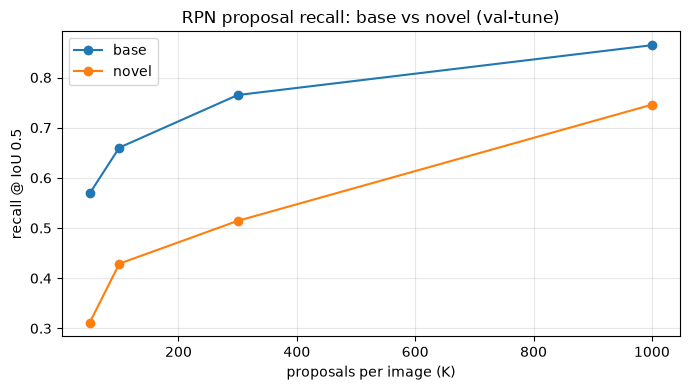

In [5]:
import matplotlib.pyplot as plt

ks = [50, 100, 300, 1000]
curve_b, curve_n = [], []
for k in ks:
    rb_list, rn_list = [], []
    for iid in val_ids:
        prop = load_proposals(iid, "outputs/proposals/val_tune")
        pb = torch.tensor(prop["boxes"][:k])
        if iid in base_gt:
            rb_list.append(recall_at(torch.stack(base_gt[iid]), pb))
        if iid in novel_gt:
            rn_list.append(recall_at(torch.stack(novel_gt[iid]), pb))
    curve_b.append(sum(rb_list) / max(len(rb_list), 1))
    curve_n.append(sum(rn_list) / max(len(rn_list), 1))

plt.figure(figsize=(7, 4))
plt.plot(ks, curve_b, marker="o", label="base")
plt.plot(ks, curve_n, marker="o", label="novel")
plt.xlabel("proposals per image (K)")
plt.ylabel("recall @ IoU 0.5")
plt.title("RPN proposal recall: base vs novel (val-tune)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
